# Tarea 3 – Aplicación Clustering

## Reconocimiento y agrupación de regímenes operativos en DAEWOO Steel Co.

**Asignatura:** Minería de Datos

**Proyecto:** *Sistema Predictivo de Gestión Energética y Alertas Operativas para DAEWOO Steel Co. mediante Minería de Datos y LangChain*

---

### Resumen

Este trabajo aplica dos técnicas a las mediciones de consumo eléctrico de una planta siderúrgica durante 2018. En la **Parte 1** se usa **KNN** (K vecinos más cercanos) con K = 3, 4, 5 y 6 para reconocer el nivel de carga de la planta (liviana, media o máxima). En la **Parte 2** se aplica **agrupación jerárquica** con tres métodos de enlace (Ward, Complete y Average) para detectar, sin usar etiquetas, los estados de operación de la planta.

KNN alcanza una exactitud cercana a **78 %** y un F1 macro cercano a **0,72** en el último trimestre del año, frente a un 51,8 % que se lograría respondiendo siempre "carga liviana". El valor de K prácticamente no influye en el resultado; lo que sí influye es la forma de ponderar a los vecinos. La principal limitación es la **confusión entre carga media y carga máxima**, que explica el 74 % de los errores. La agrupación jerárquica encuentra de forma consistente en los tres métodos **tres tipos de comportamiento** (consumo bajo con inyección capacitiva, consumo base con bajo factor de potencia y alta demanda) y uno de ellos, el primero, no está reflejado en la etiqueta de carga existente. Un anexo opcional (Anexo A) usa los grupos de Ward para identificar estados de operación ineficiente (con bajo factor de potencia) y explica su posible utilidad para el sistema de alertas del proyecto.

## 1. Introducción y contexto

### 1.1 El problema

La planta registra su consumo eléctrico **cada 15 minutos** durante todo 2018, lo que da **35.040 mediciones**. Cada medición incluye variables eléctricas (potencias reactivas y factores de potencia), el momento del día y del tipo de día, el consumo de energía y una etiqueta llamada `Load_Type` que indica el nivel de carga de la planta: **Light_Load** (liviana), **Medium_Load** (media) o **Maximum_Load** (máxima).

### 1.2 Objetivos de la tarea

**Objetivo general.** Aplicar técnicas de agrupamiento y clasificación basadas en distancia a los datos del proyecto, y evaluar qué información aportan sobre los regímenes de operación de la planta.

**Objetivos específicos.**

1. Aplicar **KNN con K = 3, 4, 5 y 6** para reconocer el nivel de carga (`Load_Type`) y comparar los resultados según el valor de K y la forma de ponderar a los vecinos.
2. Aplicar **agrupación jerárquica en tres ejecuciones**, cambiando únicamente el método de enlace (Ward, Complete y Average), y comparar la calidad de cada agrupación.
3. Analizar qué tipos de comportamiento se distinguen en los datos y cómo se relacionan con la etiqueta `Load_Type`.
4. Identificar las limitaciones de cada técnica.

**Relación con el proyecto.** Esta tarea es una etapa del proyecto de gestión energética y alertas operativas de la planta. Aquí el foco está en **estudiar las técnicas y evaluar qué tan bien funcionan**; sus resultados servirán de base para las etapas siguientes del proyecto.

### 1.3 Alcance y justificación

`Load_Type` se define a partir del consumo de energía (`Usage_kWh`). Por esa razón, el consumo **no se usa como variable predictora** en KNN (habría sido "copiar la respuesta"). El estudio reconoce el régimen de carga a partir de las demás variables, de modo que es un trabajo de **reconocimiento y explicación**, y no un pronóstico del consumo futuro. Su utilidad es:

1. mostrar si las variables eléctricas y el horario bastan para distinguir los niveles de carga;
2. descubrir tipos de comportamiento que la etiqueta existente no distingue (Parte 2);
3. servir de control cruzado: si las mediciones eléctricas no concuerdan con el consumo registrado, la diferencia puede señalar una falla de medición.

**Observación sobre las técnicas.** KNN es un método **supervisado** (necesita la etiqueta para clasificar) y no un algoritmo de agrupamiento propiamente tal; la agrupación jerárquica, en cambio, es **no supervisada**. Ambos se incluyen porque así lo plantea la tarea, y se tratan como actividades independientes.

### 1.4 Las técnicas

| Técnica | Idea central | Analogía |
|---|---|---|
| **KNN** | Para clasificar una medición nueva, se buscan las K mediciones más parecidas del pasado y se toma la clase que más se repite entre ellas. | Preguntarle a los K vecinos más parecidos qué tipo de carga tienen. |
| **Agrupación jerárquica** | Parte con cada medición como un grupo y va uniendo los dos grupos más parecidos, paso a paso, hasta formar uno solo. El resultado es un **dendrograma** (árbol de uniones) que se corta a la altura deseada. | Ordenar objetos por parecido, juntando primero los más similares. |

En KNN el parámetro K es el **número de vecinos** que votan. En la agrupación jerárquica la decisión clave es el **método de enlace**, es decir, cómo se mide la distancia entre dos grupos.

## 2. Metodología

### 2.1 Datos y variables

El conjunto de datos limpio generado en la Tarea 2 tiene 35.040 registros y 11 variables, lo que coincide con un año completo de lecturas cada 15 minutos (365 días × 96 intervalos).

**Variable a reconocer (KNN):** `Load_Type` (Light / Medium / Maximum).

**Variables predictoras (7)**, usadas tanto en KNN como en la agrupación jerárquica:

| Variable | Qué representa |
|---|---|
| `Lagging_Current_Reactive.Power_kVarh` | Energía reactiva inductiva (motores, hornos, transformadores). |
| `Leading_Current_Reactive_Power_kVarh` | Energía reactiva capacitiva. |
| `Lagging_Current_Power_Factor` | Factor de potencia inductivo (eficiencia con que se usa la energía, 0–100). |
| `Leading_Current_Power_Factor` | Factor de potencia capacitivo. |
| `WeekStatus_bin` | Día hábil (0) o fin de semana (1). |
| `NSM_sin`, `NSM_cos` | Hora del día, transformada con seno y coseno. |

### 2.2 Decisiones de diseño

- **Exclusión de variables (fuga de información).** Se excluyeron `Usage_kWh` y `CO2(tCO2)`: la etiqueta se define a partir del consumo y las emisiones son prácticamente el consumo multiplicado por una constante. Incluirlas haría el problema trivial y los resultados no serían generalizables.
- **Escalamiento.** KNN y la agrupación jerárquica funcionan con **distancias**, por lo que una variable con valores grandes (por ejemplo, los factores de potencia, de 0 a 100) dominaría sobre otra de menor magnitud. Se aplicó `StandardScaler` dentro de un `Pipeline`, ajustado **solo con los datos de entrenamiento**, para no incorporar información del conjunto de prueba.
- **Hora como seno y coseno.** Para un computador, las 23:45 (85.500 s) y las 00:00 (0 s) parecen opuestas aunque solo los separan 15 minutos. Con seno y coseno, la medianoche queda junto a la medianoche y el día se interpreta como un ciclo.
- **Partición cronológica.** Entrenamiento: enero a septiembre; prueba: octubre a diciembre. Como dos lecturas consecutivas son casi idénticas, una división al azar dejaría en el entrenamiento "gemelas" de cada caso de prueba y daría resultados optimistas. La partición cronológica reproduce el uso real: aprender del pasado y evaluar en el futuro. Como limitación, hay un solo año de datos, así que no se puede evaluar estacionalidad entre años.
- **Elección de K sin mirar la prueba.** K se compara con validación cruzada temporal (`TimeSeriesSplit`) **dentro del entrenamiento**. Si se eligiera mirando la prueba, esa evaluación dejaría de ser independiente.

### 2.3 Métricas

| Métrica | Qué mide |
|---|---|
| **Exactitud (accuracy)** | Porcentaje de mediciones bien clasificadas. |
| **F1 macro** | Desempeño promedio en las tres clases, con el mismo peso para cada una; no permite que una clase bien clasificada oculte a otra mal clasificada. |
| **F1 macro CV** | El mismo F1 calculado en validación cruzada dentro del entrenamiento; se usa para elegir K. |
| **% de empates** | Porcentaje de casos en que dos o más clases reciben igual número de votos entre los K vecinos. |
| **Coeficiente cofenético** (jerárquico) | Qué tan fielmente el dendrograma reproduce las distancias originales (valores sobre 0,8 se consideran adecuados). |
| **Silueta** (jerárquico) | Qué tan separados están los grupos entre sí (de −1 a 1; valores cercanos a 0 indican grupos que se solapan). |
| **ARI** (jerárquico) | Qué tanto coinciden dos agrupaciones distintas (1 = idénticas, 0 = sin relación). |

## 3. Parte 1: KNN con K = 3, 4, 5 y 6

### 3.1 Datos de partida

In [1]:
# Celda 3.1: carga de datos
import sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from clustering import preparacion as prep, knn

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)

df = prep.cargar_dataset_limpio()
print(df.shape)
df.head()

(35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,2018-01-01 00:00:00,3.4200,3.4600,0.0000,0.0000,70.3000,100.0000,0,Weekday,Monday,Light_Load
1,2018-01-01 00:15:00,3.1700,2.9500,0.0000,0.0000,73.2100,100.0000,900,Weekday,Monday,Light_Load
2,2018-01-01 00:30:00,4.0000,4.4600,0.0000,0.0000,66.7700,100.0000,1800,Weekday,Monday,Light_Load
3,2018-01-01 00:45:00,3.2400,3.2800,0.0000,0.0000,70.2800,100.0000,2700,Weekday,Monday,Light_Load
4,2018-01-01 01:00:00,3.3100,3.5600,0.0000,0.0000,68.0900,100.0000,3600,Weekday,Monday,Light_Load


**Resultado.** El conjunto tiene **35.040 registros y 11 columnas**. Las primeras filas corresponden al 1 de enero de 2018 (lunes, día hábil): `NSM` avanza de 900 en 900 segundos (15 minutos) y la planta opera en carga liviana, con consumos de entre 3,17 y 4,00 kWh, potencia reactiva inductiva de 2,95 a 4,46 kVarh, sin potencia reactiva capacitiva y con factor de potencia capacitivo en 100 %. Es el estado de reposo descrito en la Tarea 2 (mediana del consumo: 4,57 kWh). El conjunto está completo y listo para construir las variables predictoras y la etiqueta.

### 3.2 Partición en entrenamiento y prueba

In [2]:
# Celda 3.2: variables predictoras, partición cronológica y balance de clases
X, y, fechas = prep.preparar_clasificacion(df)
X_tr, X_te, y_tr, y_te = prep.split_cronologico(X, y, fechas)
print("Variables:", list(X.columns))
print("Train:", X_tr.shape, "| Test:", X_te.shape)
pd.DataFrame({"train %": y_tr.value_counts(normalize=True) * 100,
              "test %": y_te.value_counts(normalize=True) * 100}).round(2)

Variables: ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'WeekStatus_bin', 'NSM_sin', 'NSM_cos']
Train: (26208, 7) | Test: (8832, 7)


,train %,test %
Load_Type,,
Light_Load,51.5000,51.8100
Medium_Load,27.7200,27.5400
Maximum_Load,20.7900,20.6500


**Cómo leer la tabla.** Muestra qué porcentaje de las mediciones corresponde a cada tipo de carga en entrenamiento y en prueba.

**Resultados.**

| Clase | Entrenamiento | Prueba |
|---|---|---|
| Light_Load | 51,50 % | 51,81 % |
| Medium_Load | 27,72 % | 27,54 % |
| Maximum_Load | 20,79 % | 20,65 % |

**Interpretación.**

- Se usan **7 variables predictoras**. El entrenamiento reúne **26.208 registros** (enero–septiembre, 74,8 %) y la prueba **8.832** (octubre–diciembre, 25,2 %), exactamente 273 y 92 días de 96 lecturas.
- La composición de clases es casi idéntica en ambos periodos (la mayor diferencia es de 0,31 puntos porcentuales), por lo que la evaluación no estará sesgada por un cambio en la proporción de regímenes. Como ninguna clase es escasa (la menor supera el 20 %), no se requiere rebalanceo.
- **Referencia mínima.** Un clasificador que respondiera siempre "carga liviana" acertaría cerca de **51,8 %** en la prueba. Cualquier modelo útil debe superar ese valor con claridad.
- La similitud de proporciones no garantiza que el *comportamiento eléctrico* de cada clase sea el mismo entre ambos periodos; eso se verifica con las métricas del modelo.

### 3.3 Resultados de KNN según K y ponderación

In [3]:
# Celda 3.3: KNN con K = 3, 4, 5, 6 y dos esquemas de votación
tab_u, mod_u, pred_u = knn.evaluar_clasificacion(X_tr, X_te, y_tr, y_te, weights="uniform")
tab_d, mod_d, pred_d = knn.evaluar_clasificacion(X_tr, X_te, y_tr, y_te, weights="distance")

tabla_clf = pd.concat([tab_u, tab_d], ignore_index=True)
tabla_clf

,K,weights,Accuracy,F1_macro,F1_macro_CV(train),%Empates
0,3,uniform,0.7815,0.7204,0.8056,0.2831
1,4,uniform,0.7857,0.7222,0.8012,6.8388
2,5,uniform,0.7810,0.7185,0.8092,0.3963
3,6,uniform,0.7840,0.7197,0.8044,5.1857
4,3,distance,0.7849,0.7249,0.8082,0.2831
5,4,distance,0.7851,0.7240,0.8085,6.8388
6,5,distance,0.7834,0.7216,0.8122,0.3963
7,6,distance,0.7840,0.7224,0.8128,5.1857


**Cómo leer la tabla.** Cada fila es un KNN distinto. `K` es el número de vecinos que votan. `weights` es la forma de votar: **`uniform`**, donde cada vecino vale lo mismo, o **`distance`**, donde los vecinos más cercanos pesan más. `Accuracy` y `F1_macro` se miden en la **prueba**; `F1_macro_CV(train)` se mide en validación cruzada dentro del entrenamiento y es el que se usa para elegir K. `%Empates` indica cuántas veces los votos quedaron igualados.

**Resultados.**

| K | Ponderación | Exactitud prueba | F1 macro prueba | F1 macro CV | % empates |
|---|---|---|---|---|---|
| 3 | uniform | 0,7815 | 0,7204 | 0,8056 | 0,28 |
| 4 | uniform | 0,7857 | 0,7222 | 0,8012 | 6,84 |
| 5 | uniform | 0,7810 | 0,7185 | 0,8092 | 0,40 |
| 6 | uniform | 0,7840 | 0,7197 | 0,8044 | 5,19 |
| 3 | distance | 0,7849 | 0,7249 | 0,8082 | 0,28 |
| 4 | distance | 0,7851 | 0,7240 | 0,8085 | 6,84 |
| 5 | distance | 0,7834 | 0,7216 | 0,8122 | 0,40 |
| 6 | distance | 0,7840 | 0,7224 | 0,8128 | 5,19 |

**Interpretación.**

- **Todas las configuraciones superan con claridad la referencia de 51,8 %** (exactitud entre 0,7810 y 0,7857, unos 26 puntos porcentuales más). Las variables eléctricas, la hora y el tipo de día contienen información útil para reconocer el régimen de carga, aunque no lo determinan por completo.
- **Efecto de K: casi nulo.** La exactitud varía solo 0,47 puntos porcentuales entre la mejor y la peor configuración y no hay tendencia creciente ni decreciente. Con 8.832 registros de prueba, el error de muestreo de la exactitud ronda los 0,4 puntos porcentuales, de modo que estas diferencias son del mismo orden que la incertidumbre de la medición: **no permiten afirmar que un K sea mejor que otro**. Es coherente con los datos: al haber lecturas cada 15 minutos, los vecinos más cercanos de un registro suelen ser lecturas casi idénticas de la misma clase, y ampliar la vecindad de 3 a 6 cambia poco la decisión.
- **Efecto de la ponderación.** `distance` mejora el F1 macro en los cuatro valores de K (entre 0,0018 y 0,0045 en la escala del F1), mientras que la exactitud casi no cambia. En validación cruzada, `distance` también supera a `uniform` en los cuatro casos (hasta 0,0084 con K = 6). La ventaja es pequeña pero **consistente**.
- **Empates.** Con K = 4 son 6,84 % y con K = 6, 5,19 %, frente a 0,28 % con K = 3 y 0,40 % con K = 5. Los K pares empatan más, pero con tres clases también los K impares pueden empatar (un voto para cada clase con K = 3). El porcentaje solo depende de los vecinos, por eso es igual en ambos esquemas; la diferencia es que con `distance` el empate se resuelve según la cercanía y no de forma arbitraria. Los K pares con `uniform` son la opción menos recomendable.
- **Elección de K.** Siguiendo el criterio definido (validación cruzada, sin mirar la prueba), el mayor F1 macro CV es **K = 6 con `distance` (0,8128)**. Dado que las diferencias son mínimas, debe entenderse como una selección razonable y no como una superioridad demostrada: en la prueba esa configuración obtiene 0,7840 de exactitud y 0,7224 de F1, prácticamente equivalentes a las demás.
- **Validación frente a prueba.** El F1 macro CV (0,8012–0,8128) es cerca de **8 puntos mayor** que el de prueba (0,7185–0,7249). Esto sugiere que la relación entre las variables eléctricas y el nivel de carga **no es completamente estable en el tiempo**: el último trimestre resulta algo más difícil de clasificar. Además, el F1 macro es menor que la exactitud porque promedia las clases por igual, lo que indica que al menos una se clasifica peor que el resto; las matrices de confusión muestran cuál.

### 3.4 Matrices de confusión y métricas según K

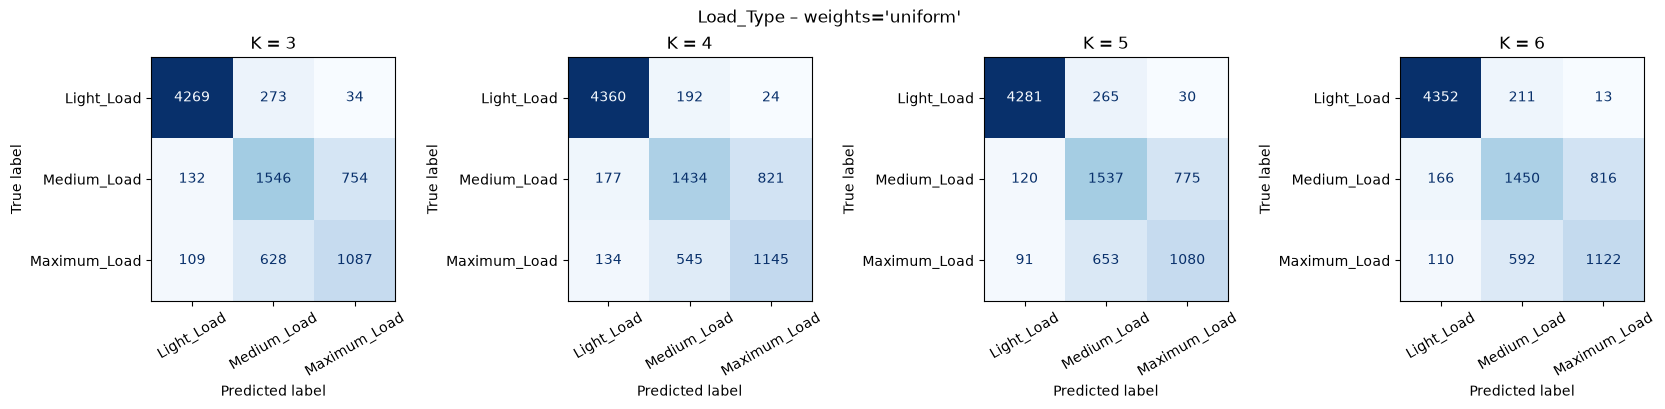

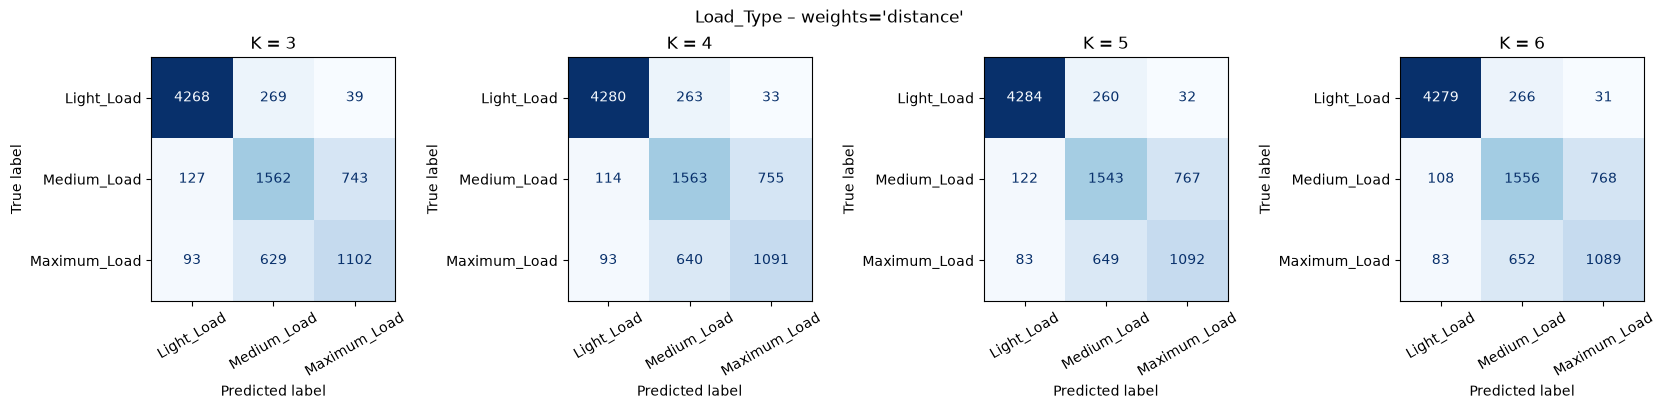

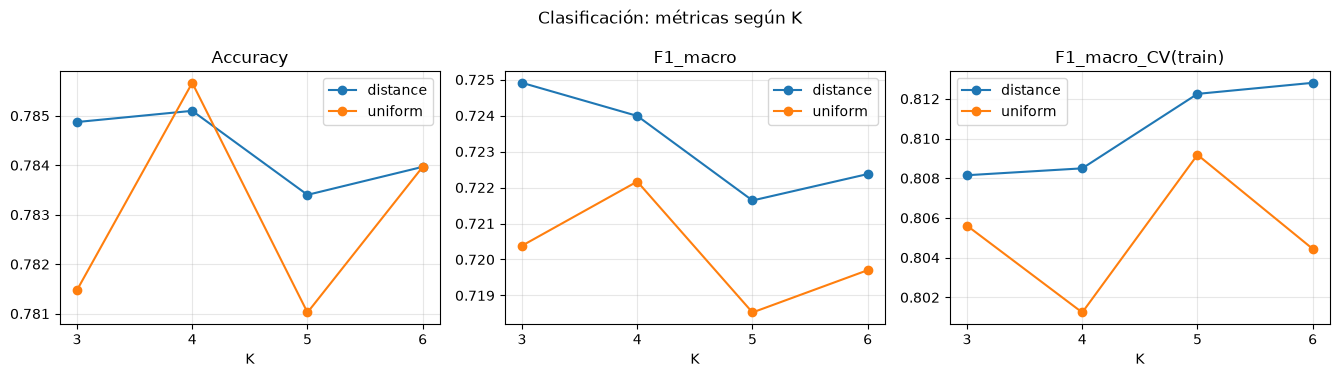

In [4]:
# Celda 3.4: matrices de confusión y curvas de métricas según K
knn.graficar_matrices_confusion(pred_u, y_te, prep.ORDEN_CARGA, "Load_Type – weights='uniform'")
knn.graficar_matrices_confusion(pred_d, y_te, prep.ORDEN_CARGA, "Load_Type – weights='distance'")
knn.graficar_metricas_vs_k(tabla_clf, ["Accuracy", "F1_macro", "F1_macro_CV(train)"],
                           "Clasificación: métricas según K")

**Cómo leer una matriz de confusión.** Las **filas** son la clase real y las **columnas**, la clase predicha. La **diagonal** contiene los aciertos; todo lo que está fuera de ella son errores. Los tonos más oscuros señalan más casos. Hay una matriz por cada K.

**Resultados para la configuración elegida (K = 6, `distance`).**

| Real \ Predicho | Light | Medium | Maximum | % acierto |
|---|---|---|---|---|
| **Light** | **4.279** | — | 31 | 93,5 % |
| **Medium** | — | **1.556** | 768 | 64,0 % |
| **Maximum** | 83 | 652 | **1.089** | 59,7 % |

**Interpretación.**

- **Desempeño muy desigual entre clases.** El régimen de reposo se reconoce con alta confiabilidad (93,5 %), mientras que los dos regímenes de mayor actividad se identifican con bastante menos (64,0 % y 59,7 %).
- **Los errores ocurren entre niveles contiguos.** De los 1.908 errores, **1.420 (74,4 %) son confusiones entre carga media y máxima**: 768 medias se predijeron como máximas y 652 máximas como medias. La confusión entre los extremos es mínima: solo 31 mediciones livianas (0,7 %) se clasificaron como máximas y 83 máximas (4,5 %) como livianas. El modelo casi nunca comete errores gruesos. Las variables eléctricas, la hora y el tipo de día separan bien el reposo de la operación activa, pero **no distinguen con nitidez el límite entre carga media y máxima**, zona en que las mediciones de ambas clases se solapan.
- **Consecuencia práctica.** Con una sensibilidad cercana al 60 % para la carga máxima, alrededor de **cuatro de cada diez intervalos de carga máxima no serían identificados como tales** (la mayoría quedaría como carga media). Un sistema de alertas basado solo en este clasificador subestimaría una parte importante de los episodios críticos.
- **Efecto de la ponderación en las matrices.** Con `uniform`, las matrices cambian de forma notoria entre K impares y pares: con K = 4 se acierta más en carga liviana (4.360) y máxima (1.145), pero menos en carga media (1.434, frente a 1.546 con K = 3). Se debe a cómo se resuelven los empates: la implementación elige según el orden alfabético de las etiquetas (Light, Maximum, Medium), lo que desfavorece sistemáticamente a Medium. Con `distance` las cuatro matrices son prácticamente idénticas (entre 1.543 y 1.563 aciertos en carga media): **ponderar por distancia hace al modelo más estable frente a K y a los empates**.

**Cómo leer los gráficos de métricas.** Cada panel muestra una métrica (exactitud, F1 macro y F1 macro de validación) según K, con una línea por esquema de ponderación. **Atención a la escala:** los ejes verticales están muy ampliados (por ejemplo, el de la exactitud abarca solo de 0,781 a 0,785, unos 0,4 puntos porcentuales), por lo que variaciones que se ven pronunciadas son en realidad diferencias mínimas.

- La curva `uniform` hace un **zigzag** entre K pares e impares, reflejo de su sensibilidad a los empates. La curva `distance` es más suave y queda por encima de `uniform` en F1 macro y en validación cruzada para todos los K.
- Las métricas de prueba y de validación **no coinciden en la tendencia**: en la prueba, el F1 macro de `distance` es mayor con K = 3 (0,7249) y baja hacia K = 5 y 6, mientras que en validación crece con K y llega a su máximo con K = 6 (0,8128). Como las diferencias son de pocas milésimas, no es posible afirmar que un K sea realmente mejor. K = 6 con `distance` es una decisión razonable bajo el criterio definido, pero debe considerarse equivalente a las demás configuraciones `distance`.

### 3.5 Conclusión de la Parte 1

KNN logra una exactitud cercana a **78 %** y un F1 macro cercano a **0,72**, claramente superiores a la referencia de 51,8 %. El valor de K prácticamente no influye; lo que marca diferencia es el esquema de ponderación (`distance` es más estable). La limitación principal es la **confusión entre carga media y máxima**, que acota su utilidad para detectar picos. El clasificador es útil como **diagnóstico del régimen operativo**, pero insuficiente por sí solo para anticipar picos de demanda.

## 4. Parte 2: Agrupación jerárquica (tres ejecuciones)

**Para qué se usa en el proyecto.** La etiqueta `Load_Type` solo clasifica la planta según cuánto consume. Un sistema de gestión energética también necesita saber **si la planta consume de forma eficiente**, y eso no lo dice la etiqueta. La agrupación jerárquica, que no usa etiquetas ni el consumo para formar los grupos, permite descubrir los estados en que opera la planta y detectar cuáles son eléctricamente ineficientes (factor de potencia bajo). Esa lectura se desarrolla en el Anexo A (opcional).

### 4.1 Diseño

- **Muestra.** Se trabaja con una muestra aleatoria de **4.000 registros** (`random_state = 42`), porque la matriz de distancias de los 35.040 registros requeriría cerca de 4,9 GB de memoria. La representatividad se verifica en 4.2.
- **Tres ejecuciones.** Cambia **únicamente el método de enlace**: **Ward**, **Complete** y **Average**, todas con distancia euclidiana y el mismo número de grupos (K = 4), de modo que las diferencias se deban solo al método.
- **Variables.** Las mismas 7 predictoras de la sección 2.1, ya escaladas (incluyen `NSM_sin` y `NSM_cos`, y `WeekStatus_bin`). `Usage_kWh` **no** se usa para formar los grupos; solo se usa después, para describirlos.
- **Qué hace cada método de enlace.**

| Método | Cómo une los grupos | Tendencia |
|---|---|---|
| **Ward** | Junta los dos grupos cuya unión aumenta menos la varianza interna. | Grupos compactos y de tamaño parecido. |
| **Complete** | Usa la distancia **máxima** entre elementos de ambos grupos. | Sensible a valores extremos; favorece grupos compactos pero puede fragmentar grupos grandes. |
| **Average** | Usa la distancia **promedio** entre todos los pares. | Punto intermedio, pero puede aislar registros muy alejados en grupos propios. |

- **Cómo se evalúa cada ejecución.** Con el dendrograma, el coeficiente cofenético, la silueta, el tamaño y el perfil de los grupos, y su cruce con `Load_Type`. Al final se comparan con una tabla resumen y el índice ARI.

### 4.2 Muestra y representatividad

In [5]:
# Celda 4.1: preparación, muestra y validación de representatividad
from sklearn.preprocessing import StandardScaler
from clustering import jerarquico

# Usa las mismas predictoras y el escalador ajustado con train que KNN.
escalador = StandardScaler().fit(X_tr)
X_scaled = pd.DataFrame(escalador.transform(X), index=X.index, columns=X.columns)

K = 4
METODOS = ["ward", "complete", "average"]

muestra = jerarquico.tomar_muestra(df, n=4000, semilla=42)
X_m = X_scaled.loc[muestra.index].to_numpy()

cols_num = ["Usage_kWh", "Lagging_Current_Reactive.Power_kVarh",
            "Leading_Current_Reactive_Power_kVarh",
            "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor", "NSM"]

medias, props = jerarquico.validar_muestra(df, muestra, cols_num)
display(medias)
display(props)

,completo,muestra,dif_%
Usage_kWh,27.3870,27.0080,-1.3850
Lagging_Current_Reactive.Power_kVarh,13.0350,12.9000,-1.0350
Leading_Current_Reactive_Power_kVarh,3.8710,3.9310,1.5420
Lagging_Current_Power_Factor,80.5800,80.5570,-0.0270
Leading_Current_Power_Factor,84.3680,83.9760,-0.4640
NSM,42750.0000,43340.4000,1.3810


,completo_%,muestra_%
Load_Type,,
Light_Load,51.5800,51.9000
Medium_Load,27.6700,26.9000
Maximum_Load,20.7500,21.2000


**Cómo leer las tablas.** La primera compara el **promedio de cada variable** en el conjunto completo y en la muestra (`dif_%` es la diferencia relativa). La segunda compara la **proporción de cada tipo de carga**.

**Interpretación.**

- Las diferencias entre medias son pequeñas: **ninguna supera el 1,6 %**. Las mayores son `Leading_Current_Reactive_Power_kVarh` (+1,54 %), `NSM` (+1,38 %) y `Usage_kWh` (−1,39 %); los factores de potencia casi no cambian.
- Son compatibles con la variación del muestreo aleatorio. Por ejemplo, en `Usage_kWh` la media de la muestra (27,01 kWh) difiere de la poblacional (27,39 kWh) en 0,38 kWh, y el error estándar con n = 4.000 y desviación de 33,44 kWh es de unos 0,53 kWh: la diferencia es **menor que un error estándar**.
- Las proporciones de `Load_Type` difieren en menos de 0,8 puntos porcentuales (Light 51,9 % vs 51,58 %, Medium 26,9 % vs 27,67 %, Maximum 21,2 % vs 20,75 %) y se conserva el orden.

**Conclusión.** La muestra (11,4 % del total) conserva la escala, la dispersión y la composición operativa de la planta, por lo que los resultados pueden extrapolarse razonablemente al total de los registros.

### 4.3 Ejecución de los tres métodos


===== WARD | cofenético=0.8247 | silueta=0.3862 =====


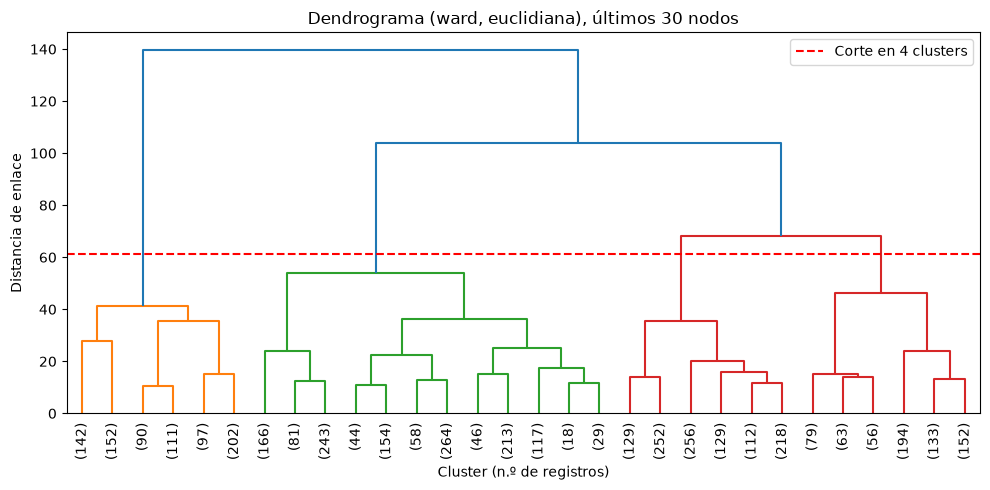

,n,%,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
cluster,,,,,,,,
1,794,19.8500,4.4200,0.1200,18.0800,99.7200,23.9000,60679.7200
2,1433,35.8300,62.8900,28.8400,0.6800,90.6300,98.1600,51824.4200
3,1096,27.4000,3.6500,4.7700,0.0200,60.3400,99.9700,27493.5200
4,677,16.9200,15.3600,7.3100,0.5500,69.5100,98.5100,30701.0300


col_0,Light_Load,Maximum_Load,Medium_Load
row_0,,,
1,45.3000,5.5000,49.1000
2,15.7000,45.5000,38.8000
3,90.5000,3.3000,6.2000
4,73.7000,17.1000,9.2000



===== COMPLETE | cofenético=0.7991 | silueta=0.2711 =====


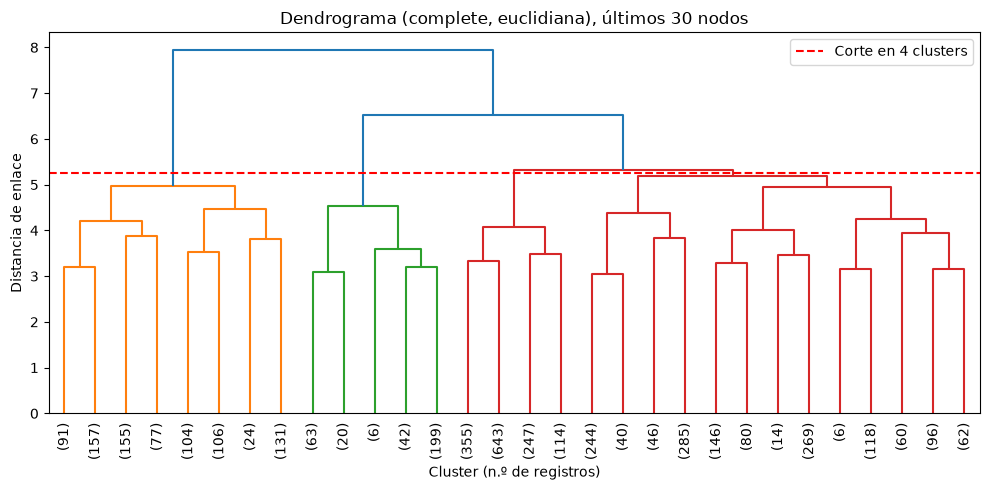

,n,%,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
cluster,,,,,,,,
1,845,21.1200,4.4300,0.0700,17.3200,99.7500,25.8900,60310.6500
2,330,8.2500,92.1700,50.2700,0.0100,86.3800,100.0000,48128.1800
3,1359,33.9800,3.4900,4.9200,0.0100,57.5600,99.9600,25686.0900
4,1466,36.6500,47.1600,19.2800,0.7300,89.5100,99.0300,48846.7900


col_0,Light_Load,Maximum_Load,Medium_Load
row_0,,,
1,46.9000,6.5000,46.6000
2,20.6000,46.1000,33.3000
3,92.9000,1.8000,5.2000
4,23.8000,42.0000,34.2000



===== AVERAGE | cofenético=0.8590 | silueta=0.3763 =====


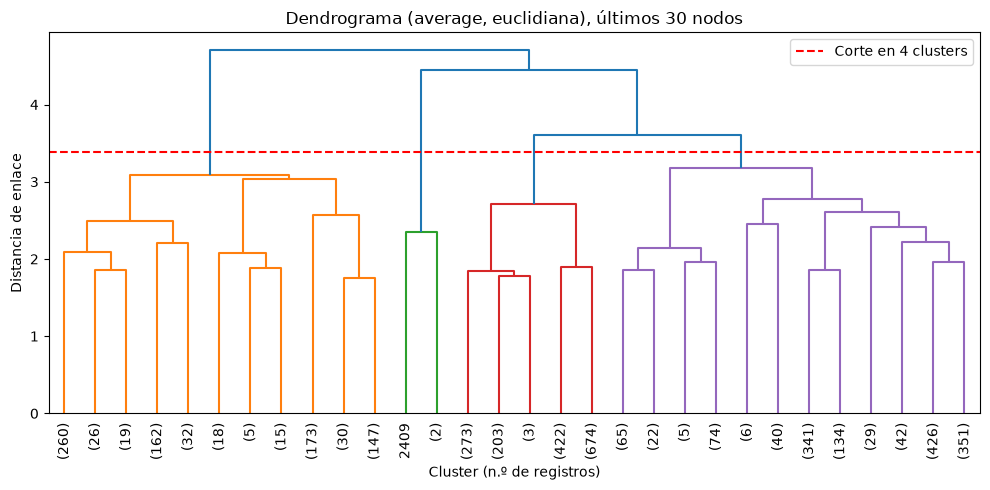

,n,%,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
cluster,,,,,,,,
1,887,22.1800,5.0000,0.1400,16.8900,99.7200,28.2400,59827.1700
2,3,0.0800,115.7200,68.5800,0.0000,84.9600,100.0000,46800.0000
3,1575,39.3800,3.5500,4.7100,0.0200,59.9500,99.9600,26689.1400
4,1535,38.3800,63.6100,28.5700,0.4700,90.6200,99.7500,50891.9200


col_0,Light_Load,Maximum_Load,Medium_Load
row_0,,,
1,46.2000,6.7000,47.1000
2,33.3000,0.0000,66.7000
3,92.4000,2.9000,4.7000
4,13.6000,48.5000,37.9000


,Método,Coef. cofenético,Silueta,Tamaños
0,ward,0.8247,0.3862,"[1433, 1096, 794, 677]"
1,complete,0.7991,0.2711,"[1466, 1359, 845, 330]"
2,average,0.8590,0.3763,"[1575, 1535, 887, 3]"


,ward,complete,average
ward,1.0000,0.5390,0.7040
complete,0.5390,1.0000,0.6940
average,0.7040,0.6940,1.0000


In [6]:
# Celda 4.2: las tres ejecuciones (dendrograma, perfil de grupos y cruce con Load_Type)
resultados = {m: jerarquico.ejecutar_jerarquico(X_m, m, K) for m in METODOS}

for m, r in resultados.items():
    print(f"\n===== {m.upper()} | cofenético={r['cofenetico']:.4f} | silueta={r['silueta']:.4f} =====")
    jerarquico.graficar_dendrograma(r["Z"], m, K)
    display(jerarquico.perfil_clusters(muestra, r["etiquetas"], cols_num))
    display(jerarquico.cruzar_con_categoria(muestra, r["etiquetas"]))

display(jerarquico.tabla_comparativa(resultados))
display(jerarquico.matriz_ari(resultados))

**Cómo leer los resultados de cada ejecución.**

- **Dendrograma.** Es un árbol de uniones: abajo están los registros (agrupados en los últimos 30 nodos para que sea legible) y arriba el momento en que los grupos se juntan. La **altura** de cada unión es la distancia entre los grupos que se unen: un salto grande significa que se unieron cosas muy distintas. La **línea punteada** es el corte en 4 grupos: cada rama que cruza esa línea es un grupo. Si el corte queda muy cerca de una unión, la separación entre esos grupos es frágil. La escala de alturas **no es comparable entre métodos**, porque cada uno define la distancia de enlace de forma distinta.
- **Perfil de los grupos.** Para cada grupo, el tamaño (`n` y `%`) y el promedio de las variables, incluyendo `Usage_kWh` (que no se usó para formarlos) y la hora media.
- **Cruce con `Load_Type`.** Qué porcentaje de cada grupo es carga liviana, media o máxima. Permite ver si los grupos descubiertos sin etiquetas se parecen a la clasificación existente.

### 4.4 Ejecución 1: enlace Ward

**Métricas.** El coeficiente cofenético es **0,8247**: el dendrograma reproduce con buena fidelidad las distancias originales. La silueta es **0,3862**, la más alta de las tres ejecuciones; indica una estructura de grupos moderada, con cierto solapamiento.

**Dendrograma.** El mayor salto (~140) aísla al grupo 1. Luego (~104) se separa el grupo 2 de los grupos 3 y 4, que se unen cerca de 68. El corte en 4 grupos (~61) queda por encima de las fusiones internas de cada grupo (≤ 54), por lo que la partición es razonable.

**Perfil de los grupos.**

| Grupo | n (%) | Usage_kWh | Reactiva inductiva (kVarh) | Reactiva capacitiva (kVarh) | FP inductivo (%) | FP capacitivo (%) | Hora media | Interpretación |
|---|---|---|---|---|---|---|---|---|
| 1 | 794 (19,85 %) | 4,42 | 0,12 | 18,08 | 99,72 | 23,90 | ~16:51 | Consumo bajo con **inyección capacitiva** activa (condensadores conectados). |
| 2 | 1.433 (35,83 %) | 62,89 | 28,84 | 0,68 | 90,63 | 98,16 | ~14:24 | **Alta demanda**, con reactiva inductiva elevada. |
| 3 | 1.096 (27,40 %) | 3,65 | 4,77 | 0,02 | 60,34 | 99,97 | ~07:38 | **Consumo base** con bajo factor de potencia inductivo. |
| 4 | 677 (16,92 %) | 15,36 | 7,31 | 0,55 | 69,51 | 98,51 | ~08:32 | **Estado de fin de semana** con consumo intermedio y factor de potencia inductivo bajo (100 % sábado y domingo, ver Anexo A). |

**Cruce con `Load_Type`.** El grupo 2 concentra la carga máxima (45,5 % Maximum y 38,8 % Medium). Los grupos 3 y 4 son mayoritariamente carga liviana (90,5 % y 73,7 %). El grupo 1 se reparte casi por igual entre liviana (45,3 %) y media (49,1 %) pese a su consumo bajo: captura un **comportamiento eléctrico (reactiva capacitiva) que `Load_Type` no distingue**.

### 4.5 Ejecución 2: enlace Complete

**Métricas.** Cofenético **0,7991**, el más bajo de las tres y levemente bajo el 0,8: el dendrograma es menos fiel a las distancias originales. Silueta **0,2711**, también la más baja: los grupos están poco separados.

**Dendrograma.** La escala (máx. ~8) no es comparable con la de Ward. El corte en 4 grupos (~5,25) queda muy cerca de las fusiones de la rama roja (~5,2–5,3), por lo que la separación entre los grupos 3 y 4 es **frágil**.

**Perfil de los grupos.**

| Grupo | n (%) | Usage_kWh | Reactiva inductiva (kVarh) | Reactiva capacitiva (kVarh) | FP inductivo (%) | FP capacitivo (%) | Hora media | Interpretación |
|---|---|---|---|---|---|---|---|---|
| 1 | 845 (21,12 %) | 4,43 | 0,07 | 17,32 | 99,75 | 25,89 | ~16:45 | Consumo bajo con inyección capacitiva. |
| 2 | 330 (8,25 %) | 92,17 | 50,27 | 0,01 | 86,38 | 100,00 | ~13:22 | **Picos de alta demanda.** |
| 3 | 1.359 (33,98 %) | 3,49 | 4,92 | 0,01 | 57,56 | 99,96 | ~07:08 | Consumo base con bajo factor de potencia. |
| 4 | 1.466 (36,65 %) | 47,16 | 19,28 | 0,73 | 89,51 | 99,03 | ~13:34 | Demanda media-alta. |

**Cruce con `Load_Type`.** El grupo 3 es 92,9 % carga liviana. Los grupos 2 y 4 combinan carga máxima (46,1 % y 42,0 %) y media (33,3 % y 34,2 %). **Aporte del método:** separa la demanda alta en dos niveles (~92 kWh y ~47 kWh), aislando un grupo pequeño de picos extremos.

### 4.6 Ejecución 3: enlace Average

**Métricas.** Cofenético **0,8590**, el más alto, algo esperable porque este método tiende a preservar las distancias promedio. Silueta **0,3763**, similar a Ward. Esta cifra debe leerse con cautela: el grupo 2 tiene solo **3 registros**, así que la partición equivale en la práctica a **3 grupos reales**.

**Dendrograma.** El grupo 2 (verde) está formado por un registro y un grupo de 2, y se une al resto a una distancia alta (~4,5). Es un grupo marginal que el método separa por ser extremo, no una condición operativa recurrente.

**Perfil de los grupos.**

| Grupo | n (%) | Usage_kWh | Reactiva inductiva (kVarh) | Reactiva capacitiva (kVarh) | FP inductivo (%) | FP capacitivo (%) | Hora media | Interpretación |
|---|---|---|---|---|---|---|---|---|
| 1 | 887 (22,18 %) | 5,00 | 0,14 | 16,89 | 99,72 | 28,24 | ~16:37 | Consumo bajo con inyección capacitiva. |
| 2 | 3 (0,08 %) | 115,72 | 68,58 | 0,00 | 84,96 | 100,00 | ~13:00 | **Grupo marginal:** tres picos extremos. |
| 3 | 1.575 (39,38 %) | 3,55 | 4,71 | 0,02 | 59,95 | 99,96 | ~07:25 | Consumo base con bajo factor de potencia. |
| 4 | 1.535 (38,38 %) | 63,61 | 28,57 | 0,47 | 90,62 | 99,75 | ~14:08 | Alta demanda. |

**Cruce con `Load_Type`.** Los grupos 3 y 4 repiten el patrón anterior (92,4 % de carga liviana en el 3; 48,5 % máxima y 37,9 % media en el 4). El grupo 2, con solo 3 registros, no permite sacar conclusiones.

### 4.7 Comparación de las tres ejecuciones

| Método | Coef. cofenético | Silueta | Tamaños de los grupos |
|---|---|---|---|
| Ward | 0,8247 | **0,3862** | 1.433 / 1.096 / 794 / 677 |
| Complete | 0,7991 | 0,2711 | 1.466 / 1.359 / 845 / 330 |
| Average | **0,8590** | 0,3763 | 1.575 / 1.535 / 887 / 3 |

**Índice de Rand ajustado (ARI):**  mide cuánto coinciden dos agrupaciones: Ward–Average **0,704**, Complete–Average **0,694**, Ward–Complete **0,539**. Los tres métodos coinciden en una parte importante de la estructura; la mayor discrepancia es entre Ward y Complete.

**Grupos estables.** Tres tipos de comportamiento aparecen con perfiles casi idénticos en las tres ejecuciones:

1. **Consumo bajo con inyección capacitiva** (~4–5 kWh, factor de potencia capacitivo ~24–28 %, ~20–22 % de la muestra).
2. **Consumo base con factor de potencia inductivo bajo** (~3,5 kWh, factor de potencia inductivo ~58–60 %, ~27–39 %).
3. **Alta demanda** (≥ 47 kWh, ~8–38 %).

Esa consistencia indica que **la estructura es estable entre métodos** (no depende de un algoritmo en particular); como la silueta es moderada (0,27–0,39), debe tomarse como una descripción orientativa. Lo que cambia entre métodos es cómo se reparte la zona de demanda media y alta.

**Elección del método.**

- **Ward:** mejor silueta, grupos equilibrados e interpretables, y es el único que separa un estado propio de fin de semana (grupo 4, ~15 kWh, 100 % sábado y domingo, ver Anexo A).
- **Average:** mejor cofenético, pero genera un grupo de 3 registros que no aporta información operativa.
- **Complete:** métricas más débiles, pero aísla un grupo de picos extremos (330 registros, 92 kWh).

Un dato relevante: los grupos se formaron **sin usar el consumo**, y aun así separan niveles de consumo muy distintos. Esto confirma que las variables eléctricas y horarias reflejan el régimen operativo.

**Relación con los estados de interés del proyecto.**

- **Pico de alta demanda:** grupo 2 de Ward (62,9 kWh) y grupo 2 de Complete (92,2 kWh; 8,25 % de los registros); ambos concentran la mayor parte de la carga máxima.
- **Consumo ineficiente:** los grupos con consumo bajo y factor de potencia inductivo de 57–70 % (grupo 3 en las tres ejecuciones y grupo 4 de Ward): la planta consume poco, pero con mala eficiencia eléctrica.
- **Operación normal:** no tiene un grupo propio; lo más cercano son las demandas medias-altas (grupo 4 de Complete y de Average).
- **Hallazgo adicional:** el grupo de **consumo bajo con inyección capacitiva** no estaba previsto en la definición inicial de estados, y `Load_Type` no lo distingue (se reparte entre liviana y media), por lo que aporta información nueva respecto de la etiqueta existente.

**Limitaciones.**

- El número de grupos se fijó en 4 por comparabilidad, sin optimizarlo.
- La silueta (0,27–0,39) indica una separación de **débil a moderada**.
- La hora se representa con seno y coseno, lo que respeta su carácter circular; en cambio, la **hora media** de la tabla de perfiles es un promedio simple de `NSM` y debe leerse como orientativa.

## 5. Discusión y conclusiones

### 5.1 Respecto de lo solicitado en la tarea

- **KNN con K = 3, 4, 5 y 6.** El desempeño es prácticamente el mismo con los cuatro valores (exactitud 0,781–0,786, F1 macro 0,719–0,725). El valor de K no marca diferencia; sí la ponderación por distancia, que es más estable y resuelve mejor los empates.
- **Agrupación jerárquica, tres ejecuciones.** Ward, Complete y Average coinciden en la estructura principal de los datos. Ward ofrece la mejor silueta y los grupos más interpretables; Average, el mejor cofenético pero con un grupo marginal de 3 registros; Complete aísla los picos extremos.

### 5.2 Qué se puede rescatar de este trabajo

1. **Las variables eléctricas y horarias bastan para distinguir el reposo de la operación activa.** KNN reconoce la carga liviana con 93,5 % de acierto, y la agrupación jerárquica separa grupos de consumo muy distinto sin haber usado el consumo.
2. **La frontera entre carga media y máxima es difusa.** Las tres cuartas partes de los errores de KNN están ahí. Con estas variables, un clasificador no puede separar bien esos dos niveles, y por ello no basta por sí solo para alertar de picos.
3. **Los datos tienen más estructura que la etiqueta.** La agrupación encuentra estados que `Load_Type` no distingue; por ejemplo, estados con bajo factor de potencia que ocurren en momentos distintos de la semana (ver Anexo A).
4. **Hay tres comportamientos estables.** Aparecen en los tres métodos con perfiles casi idénticos, lo que indica que no dependen de un algoritmo en particular (con la salvedad de la silueta moderada).
5. **Cada técnica cumple un rol distinto.** KNN sirve como diagnóstico del régimen operativo; la agrupación jerárquica, como herramienta de exploración para descubrir estados de operación.

### 5.3 Conexión con el proyecto

- **Lo que la Parte 1 deja claro:** con las variables eléctricas y el horario se reconoce bien la carga liviana (93,5 %), pero no la frontera entre carga media y máxima (~60 % de acierto en la máxima). Es decir, estas variables **no bastan para alertar de picos**, lo que justifica el pronóstico basado en el consumo previo que se desarrolla en la Tarea 4.
- **Lo que la Parte 2 agrega:** estados de operación que la etiqueta no distingue. El Anexo A analiza, de forma complementaria, los estados con bajo factor de potencia y su posible uso en alertas de eficiencia eléctrica.
- **Cómo se combinan:** el sistema de alertas del proyecto se apoyará en el pronóstico de carga de la Tarea 4 (anticipar la carga máxima) y en los estados de esta tarea (detectar operación ineficiente, ver Anexo A).

**En síntesis,** el aporte de esta tarea al proyecto es de **diagnóstico y exploración**: no entrega un modelo de alerta listo, sino conocimiento sobre qué distinguen las variables disponibles y qué estados de operación existen, sobre lo cual se construyen las etapas siguientes.

### 5.4 Limitaciones

- **Un solo año de datos** y una sola planta: no se evalúa estacionalidad entre años.
- **El último trimestre es más difícil** que los meses de entrenamiento (F1 de validación ≈ 0,80 frente a ≈ 0,72 en la prueba).
- La agrupación jerárquica se hizo sobre **una muestra de 4.000 registros** y con K = 4 fijo.
- La **silueta es baja** (0,27–0,39): los grupos no están claramente separados.
- KNN es un método supervisado y no pronostica consumo futuro; su alcance es el descrito en 1.3.


### Anexo A. Aplicación al proyecto: estados operativos ineficientes

> **Sección complementaria.** Esta tarea pide aplicar KNN y agrupación jerárquica, y eso está completo en las secciones 3 y 4. Este anexo no es necesario para cumplir lo solicitado: explica qué utilidad tienen los grupos de Ward para el proyecto de gestión energética. Puede omitirse sin perder el hilo del informe.

**Para qué sirve en el proyecto.** La etiqueta `Load_Type` solo indica cuánto consume la planta. Un sistema de gestión energética también necesita saber si la planta opera de forma eficiente, y los grupos descubiertos sin etiquetas lo permiten: identifican estados con factor de potencia bajo, que podrían usarse para alertas de eficiencia eléctrica, independientes de las alertas de carga máxima.


**Objetivo.** Usar los cuatro grupos de la ejecución Ward (la de mejor silueta) para responder: *¿en qué estados opera la planta con bajo factor de potencia, qué parte del tiempo y del consumo representan, y cuándo ocurren?* Un factor de potencia bajo significa que se usa más energía reactiva por cada unidad de energía útil, y en tarifas industriales suele traducirse en penalizaciones o pérdidas (el efecto concreto depende de la tarifa de la planta, que no forma parte de los datos).

**Criterio.** Se marca un estado como **ineficiente** si su factor de potencia inductivo medio es menor a 80 % o el capacitivo, menor a 50 %. El resto se toma como referencia. Los porcentajes se calculan sobre la muestra de 4.000 registros (11,4 % del total), que en 4.2 resultó representativa; por lo tanto, son aproximados.

,Estado,¿Ineficiente?,% de registros,% del consumo total,Consumo medio (kWh),FP inductivo medio (%),FP capacitivo medio (%),Horas del 50 % central,% en fin de semana
0,Alta demanda (referencia),No,35.8000,83.4000,62.9000,90.6000,98.2000,10.8–18.0 h,2.4000
1,Consumo base con FP inductivo bajo,Sí,27.4000,3.7000,3.7000,60.3000,100.0000,2.5–7.5 h,0.0000
2,Consumo bajo con inyección capacitiva,Sí,19.9000,3.3000,4.4000,99.7000,23.9000,12.8–20.8 h,55.5000
3,Consumo medio (fin de semana) con FP inductivo...,Sí,16.9000,9.6000,15.4000,69.5000,98.5000,3.5–11.8 h,100.0000


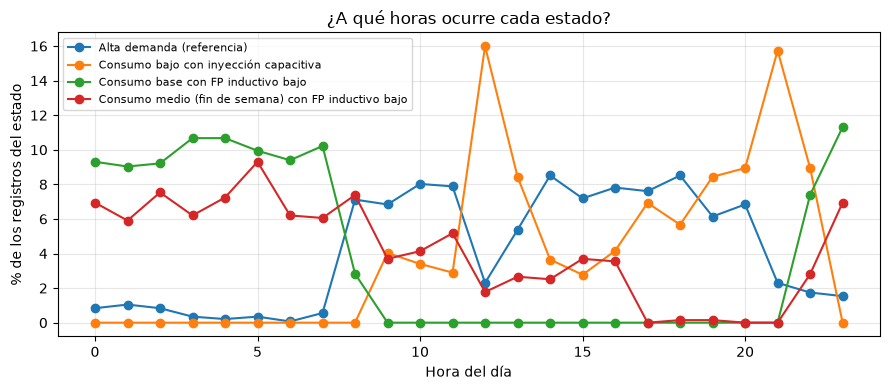

In [7]:
# Celda A.1: estados operativos ineficientes (a partir de la ejecución Ward)
# Un estado se considera ineficiente si su factor de potencia inductivo medio es < 80 % o el capacitivo < 50 %.
import numpy as np
import matplotlib.pyplot as plt

etq = resultados["ward"]["etiquetas"]
m = muestra.copy()
m["grupo"] = etq
m["hora"] = m["NSM"] / 3600
m["finde"] = m["WeekStatus_bin"] == 1 if "WeekStatus_bin" in m else m["WeekStatus"].eq("Weekend")

perf = m.groupby("grupo").agg(
    kwh=("Usage_kWh", "mean"),
    fp_ind=("Lagging_Current_Power_Factor", "mean"),
    fp_cap=("Leading_Current_Power_Factor", "mean"))

def nombre_estado(f):
    if f.kwh > 40:
        return "Alta demanda (referencia)"
    if f.fp_cap < 50:
        return "Consumo bajo con inyección capacitiva"
    if f.fp_ind < 65:
        return "Consumo base con FP inductivo bajo"
    return "Consumo medio (fin de semana) con FP inductivo bajo"

m["estado"] = m["grupo"].map(perf.apply(nombre_estado, axis=1))

total_kwh = m["Usage_kWh"].sum()
filas = []
for est, g in m.groupby("estado"):
    ineficiente = (g["Lagging_Current_Power_Factor"].mean() < 80) or (g["Leading_Current_Power_Factor"].mean() < 50)
    filas.append({
        "Estado": est,
        "¿Ineficiente?": "Sí" if ineficiente else "No",
        "% de registros": round(100 * len(g) / len(m), 1),
        "% del consumo total": round(100 * g["Usage_kWh"].sum() / total_kwh, 1),
        "Consumo medio (kWh)": round(g["Usage_kWh"].mean(), 1),
        "FP inductivo medio (%)": round(g["Lagging_Current_Power_Factor"].mean(), 1),
        "FP capacitivo medio (%)": round(g["Leading_Current_Power_Factor"].mean(), 1),
        "Horas del 50 % central": f"{g['hora'].quantile(.25):.1f}–{g['hora'].quantile(.75):.1f} h",
        "% en fin de semana": round(100 * g["finde"].mean(), 1),
    })
tabla_estados = pd.DataFrame(filas).sort_values("% de registros", ascending=False).reset_index(drop=True)
display(tabla_estados)

# distribución horaria de cada estado
fig, ax = plt.subplots(figsize=(9, 4))
for est, g in m.groupby("estado"):
    ax.plot(np.arange(24), np.bincount(g["hora"].astype(int).clip(0, 23), minlength=24) / len(g) * 100,
            marker="o", label=est)
ax.set_xlabel("Hora del día")
ax.set_ylabel("% de los registros del estado")
ax.set_title("¿A qué horas ocurre cada estado?")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Cómo leer la tabla y el gráfico.** Cada fila es uno de los cuatro grupos de Ward. `% de registros` es la fracción del tiempo que la planta pasa en ese estado y `% del consumo total`, la fracción de la energía que consume en él. `Horas del 50 % central` indica entre qué horas ocurre la mitad central de sus registros. El gráfico muestra, para cada estado, a qué horas del día aparece.

**Resultados.**

| Estado | ¿Ineficiente? | % registros | % del consumo | FP inductivo / capacitivo (%) | Cuándo ocurre |
|---|---|---|---|---|---|
| Alta demanda (referencia) | No | 35,8 | **83,4** | 90,6 / 98,2 | Días hábiles, entre las 10:48 y las 18:00 h (centro) |
| Consumo base con FP inductivo bajo | **Sí** | 27,4 | 3,7 | **60,3** / 100 | Días hábiles, noche y madrugada (principalmente entre las 22 y las 7 h) |
| Consumo bajo con inyección capacitiva | **Sí** | 19,9 | 3,3 | 99,7 / **23,9** | Entre las 8 y las 23 h, con puntas a las 12 y a las 21 h; 55,5 % en fin de semana |
| Consumo medio con FP inductivo bajo | **Sí** | 16,9 | 9,6 | **69,5** / 98,5 | Solo sábado y domingo, sobre todo antes del mediodía |

**Interpretación.**

- **Los tres estados ineficientes suman el 64,2 % de los registros, pero solo el 16,6 % del consumo.** La planta pasa mucho tiempo en estados de poca energía con mala eficiencia eléctrica, mientras que el 83,4 % de la energía se consume en alta demanda, con factor de potencia de 90,6 %.
- **Cada ineficiencia tiene un momento propio.** El factor de potencia inductivo bajo aparece en la **noche y madrugada de días hábiles** (60 %) y en los **fines de semana** (70 %): la planta opera con poca carga, lo que es compatible con equipos inductivos energizados con poca carga útil (hipótesis, no medida en los datos). En cambio, el factor de potencia **capacitivo** bajo (24 %) aparece **de día y de tarde–noche**, cuando la planta tiene poca carga: es compatible con una sobrecompensación por condensadores conectados, pero esto es una hipótesis que habría que confirmar con el personal de la planta.
- **El grupo 4 es un estado de fin de semana** (100 % sábado y domingo). Su hora media (~08:30 h) no es representativa, porque `NSM` es una variable circular y su promedio simple no describe el horario real.
- **Lo que no se puede afirmar.** No se midió el costo de estas ineficiencias, y los porcentajes provienen de una muestra. Además, la silueta moderada (0,39 en Ward) indica que las fronteras entre estados no son nítidas.

**Utilidad para el proyecto.** Los estados dan reglas concretas para alertas de eficiencia, independientes de las alertas de carga: por ejemplo, avisar cuando la planta opera de madrugada en un día hábil con factor de potencia inductivo cercano a 60 %, o cuando se detecta factor de potencia capacitivo bajo en horas de poca carga.